[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/MFM/blob/main/Quantlets/Ch_14/MFM_ch14_m6_competition/MFM_ch14_m6_competition.ipynb)

# MFM_ch14_m6_competition

Case study, Makridakis, Spiliotis, Hollyman, Petropoulos, Swanson and Gaba (2025), The M6 forecasting competition: bridging the gap between forecasting and investment decisions, on course data: the 19 M6 assets available in data/market (AMZN, JPM, META, HYG, IEF, IWM, LQD, SHY, TLT and the ten XL* sector ETFs), four-week periods on the M6 calendar (the 12 competition periods, March 2022 to February 2023, and 93 periods from July 2019), probabilities that each asset's total return falls in each quintile of the universe, ranked probability score (RPS) against equal probabilities of 0.2; forecasters: historical mean and covariance, volatility only (EWMA, zero mean), a small network (4, 8, 5) trained on all earlier periods with the RPS as loss; Diebold-Mariano tests on the per-period RPS differences.

> **Working in Google Colab? Save your own copy first.**
> The Colab link opens a temporary copy: when you close the tab or the session times out, your changes are lost.
> Use **File → Save a copy in Drive** (it goes to the *Colab Notebooks* folder of your ASE Google Drive) and work in that copy.
> For the team project, **File → Save a copy in GitHub** puts the notebook directly in your team's repository.
> Files you create while the notebook runs (CSV, charts) are also temporary: set `SAVE_TO_DRIVE = True` in the next cell to keep them.

In [1]:
# Optional (Colab only): keep the files you create in Google Drive
SAVE_TO_DRIVE = False   # set to True, run this cell and allow access to your Drive

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/MFM/Chapter_14'
    os.makedirs(OUT_DIR, exist_ok=True)
print('Save your outputs to:', os.path.abspath(OUT_DIR))


Save your outputs to: /Users/danpele/Documents/2026 MFM/MFM/Quantlets/Ch_14/MFM_ch14_m6_competition


In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
import torch
import warnings
warnings.filterwarnings('ignore')

## Data and tests

In [3]:
REPO_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/data/market/'
# local copy of data/market when the notebook runs inside the repository
MARKET_DIR = next((os.path.join(d, 'data', 'market') for d in ('.', '..', '../..', '../../..')
                   if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def read_market(symbol):
    """Read data/market/<SYMBOL>.csv locally or from the GitHub repository."""
    fname = f'{symbol}.csv'
    path = os.path.join(MARKET_DIR, fname)
    src = path if os.path.exists(path) else REPO_RAW + fname
    return pd.read_csv(src, index_col='date', parse_dates=True).sort_index()


def nw_var(d, lags=None):
    """Long-run variance (Newey-West, Bartlett kernel, autocovariances divided by T)."""
    d = np.asarray(d, float) - np.mean(d)
    T = len(d)
    if lags is None:
        lags = int(np.floor(4 * (T / 100) ** (2 / 9)))
    v = np.mean(d ** 2)
    for j in range(1, lags + 1):
        v += 2 * (1 - j / (lags + 1)) * np.sum(d[j:] * d[:-j]) / T
    return v


def diebold_mariano(la, lb, lags=None):
    """DM = mean(d) / sqrt(LRV/T), d = la - lb; negative => A has the lower mean loss."""
    d = np.asarray(la, float) - np.asarray(lb, float)
    dm = d.mean() / np.sqrt(nw_var(d, lags) / len(d))
    return dict(dbar=float(d.mean()), DM=float(dm), p=float(2 * stats.norm.sf(abs(dm))))

## Style

In [4]:
plt.rcParams.update({'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none',
                     'savefig.transparent': True, 'axes.grid': False, 'font.family': 'sans-serif',
                     'font.sans-serif': ['Helvetica', 'Arial', 'DejaVu Sans'], 'font.size': 9, 'axes.labelsize': 10,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6,
                     'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 8})
MainBlue, IDAred, Forest, Amber, Navy, BandBlue = '#1A3A6E', '#CD0000', '#2E7D32', '#B5853F', '#1F2A44', '#C5D2E8'


def save_fig(name):
    plt.savefig(os.path.join(OUT_DIR, f'{name}.pdf'), bbox_inches='tight', transparent=True)
    plt.savefig(os.path.join(OUT_DIR, f'{name}.png'), bbox_inches='tight', transparent=True, dpi=180)
    plt.show()


def fig_legend_bottom(fig, handles, labels, ncol=3, y=0.0):
    fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


class _G:   # the names used by the chapter code
    pass
g = _G()
g.MainBlue, g.IDAred, g.Forest, g.Amber, g.Navy, g.BandBlue = MainBlue, IDAred, Forest, Amber, Navy, BandBlue
g.save_fig, g.fig_legend_bottom = save_fig, fig_legend_bottom


class _M:
    pass
M = _M()
M.read_market, M.diebold_mariano = read_market, diebold_mariano

## Settings

In [5]:
HERE = OUT_DIR
ASSETS = ['AMZN', 'JPM', 'META', 'HYG', 'IEF', 'IWM', 'LQD', 'SHY', 'TLT',
          'XLB', 'XLC', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLU', 'XLV', 'XLY']
M6_BASE = ['2022-03-04', '2022-04-01', '2022-04-29', '2022-05-27', '2022-06-24', '2022-07-22', '2022-08-19',
           '2022-09-16', '2022-10-14', '2022-11-11', '2022-12-09', '2023-01-06', '2023-02-03']
EXT_FROM = '2019-07-01'
TRAIN_FROM = '2004-01-01'
NSIM = 20000
LAM = 0.94
MODELS = ['HM', 'VOL', 'NN']
LBL = {'U': 'Equal probabilities (benchmark)', 'HM': 'Historical mean and covariance',
       'VOL': 'Volatility only (EWMA, zero mean)', 'NN': 'Small network (4, 8, 5)'}
COL = {'HM': g.Amber, 'VOL': g.MainBlue, 'NN': g.Forest}
PAPER = dict(bench=0.16, median=0.162, mean=0.179, n_teams=163, beat=38, beat_share=23.3)

## Quintiles, RPS and the forecasters

In [6]:
def prices():
    P = pd.concat({a: M.read_market(f'{a}.US')['adjusted_close'] for a in ASSETS}, axis=1).sort_index()
    return P[P.index >= '2002-01-01']

In [7]:
def realised_q(R):
    """Fractional quintile membership (N x 5) of the realised returns R (N,): position r covers [(r-1)/N, r/N]."""
    N = len(R)
    pos = np.empty(N)
    pos[np.argsort(R, kind='mergesort')] = np.arange(N)
    lo, hi = pos / N, (pos + 1) / N
    k0, k1 = np.arange(5) / 5, np.arange(1, 6) / 5
    q = np.clip(np.minimum(hi[:, None], k1) - np.maximum(lo[:, None], k0), 0, None) * N
    return q

In [8]:
def rps(q, f):
    """Ranked probability score of each asset (eq. 1): mean over j of (cumsum q - cumsum f)^2."""
    return ((np.cumsum(q, 1) - np.cumsum(f, 1)) ** 2).mean(1)

In [9]:
def sim_probs(mu, S, rng):
    """Quintile probabilities from NSIM Normal draws of the h-day return vector (rank-based, fractional)."""
    N = len(mu)
    Z = rng.multivariate_normal(mu, S, size=NSIM, method='cholesky')
    pos = np.argsort(np.argsort(Z, 1), 1)
    lo, hi = pos / N, (pos + 1) / N
    k0, k1 = np.arange(5) / 5, np.arange(1, 6) / 5
    q = np.clip(np.minimum(hi[..., None], k1) - np.maximum(lo[..., None], k0), 0, None) * N
    return q.mean(0)

In [10]:
def ewma_cov(X, lam=LAM):
    S = np.cov(X[:60].T)
    for x in X[60:]:
        S = lam * S + (1 - lam) * np.outer(x, x)
    return S

In [11]:
def periods(idx):
    """Four-week periods on the M6 calendar: base dates 4 March 2022 + 28k days (last trading day on or before),
    consecutive pairs. Returns the 12 M6 periods, the evaluation periods from EXT_FROM (the M6 periods among them)
    and the training periods of the network from TRAIN_FROM, as (i0, i1) positions."""
    d0 = pd.Timestamp(M6_BASE[0])
    ks = range(-int((d0 - pd.Timestamp(TRAIN_FROM)).days // 28), int((idx[-1] - d0).days // 28) + 1)
    pos = sorted({int(np.searchsorted(idx, d0 + pd.Timedelta(days=28 * k), side='right') - 1) for k in ks})
    pairs = list(zip(pos[:-1], pos[1:]))
    m6b = [int(idx.get_indexer([pd.Timestamp(d)])[0]) for d in M6_BASE]
    assert min(m6b) >= 0
    m6 = list(zip(m6b[:-1], m6b[1:]))
    assert all(p in pairs for p in m6)
    ext = [p for p in pairs if idx[p[0]] >= pd.Timestamp(EXT_FROM)]
    return m6, ext, pairs

In [12]:
def features(L, i0, ok):
    """Cross-sectionally standardised features at base position i0 for the available assets ok."""
    x = L[i0 - 249:i0 + 1][:, ok]
    f = np.column_stack([np.log(x[-20:].std(0)), np.log(x.std(0)), x[-20:].sum(0), x.sum(0)])
    return (f - f.mean(0)) / f.std(0)

In [13]:
def nn_fit(Xs, Qs, seed):
    """4 -> 8 -> 5 network (tanh, softmax), mean RPS as loss, Adam, 300 epochs, 10 initialisations averaged."""
    import torch
    torch.manual_seed(seed)
    X = torch.tensor(np.vstack(Xs), dtype=torch.float32)
    Q = torch.tensor(np.vstack(Qs), dtype=torch.float32)
    nets = []
    for s in range(10):
        net = torch.nn.Sequential(torch.nn.Linear(4, 8), torch.nn.Tanh(), torch.nn.Linear(8, 5))
        opt = torch.optim.Adam(net.parameters(), lr=1e-2, weight_decay=1e-3)
        for _ in range(300):
            opt.zero_grad()
            p = torch.softmax(net(X), 1)
            loss = ((torch.cumsum(Q, 1) - torch.cumsum(p, 1)) ** 2).mean()
            loss.backward()
            opt.step()
        nets.append(net)

    def predict(Xn):
        with torch.no_grad():
            Z = torch.tensor(Xn, dtype=torch.float32)
            return np.mean([torch.softmax(n(Z), 1).numpy() for n in nets], 0)
    return predict

## Evaluation

In [14]:
def run():
    P = prices()
    idx = P.index
    L = np.log(P).diff().values
    m6, ext, allp = periods(idx)
    rng = np.random.default_rng(14)
    eval_p = sorted(set(m6) | set(ext))
    out = {}
    # training sample of the network: every four-week period from 2004 (assets present over the whole window)
    train = []
    for i0, i1 in allp:
        ok = np.isfinite(L[i0 - 249:i1 + 1]).all(0) & np.isfinite(P.values[i0]) & np.isfinite(P.values[i1])
        if ok.sum() < 10:
            continue
        R = P.values[i1, ok] / P.values[i0, ok] - 1
        train.append((i0, i1, features(L, i0, ok), realised_q(R)))
    year_fit = {}
    for i0, i1 in eval_p:
        ok = np.isfinite(L[i0 - 249:i1 + 1]).all(0)
        assert ok.all(), idx[i0]
        R = P.values[i1] / P.values[i0] - 1
        q = realised_q(R)
        X = L[i0 - 249:i0 + 1]
        h = i1 - i0                                    # trading days in the period
        mu = h * X.mean(0)
        S250 = h * np.cov(X.T)
        Sew = h * ewma_cov(X)
        fU = np.full((len(ASSETS), 5), 0.2)
        fHM = sim_probs(mu, S250, rng)
        fVOL = sim_probs(np.zeros(len(ASSETS)), Sew, rng)
        y = idx[i0].year
        if y not in year_fit:     # re-estimated at the start of each year, on the blocks that ended before
            past = [t for t in train if t[1] <= i0]
            year_fit[y] = nn_fit([t[2] for t in past], [t[3] for t in past], seed=y)
            print(f'   NN {y}: {len(past)} training blocks')
        fNN = year_fit[y](features(L, i0, np.ones(len(ASSETS), bool)))
        f = dict(U=fU, HM=fHM, VOL=fVOL, NN=fNN)
        out[(i0, i1)] = dict(start=str(idx[i0].date()), end=str(idx[i1].date()), R=R, q=q,
                             f=f, rps={m: float(rps(q, v).mean()) for m, v in f.items()},
                             vol=np.sqrt(np.diag(Sew) / h * 252))
    return idx, m6, ext, out

In [15]:
def summarise(m6, ext, out):
    res = {'assets': ASSETS, 'paper': PAPER, 'n_assets': len(ASSETS)}
    for name, per in (('m6', m6), ('ext', ext)):
        D = pd.DataFrame([out[p]['rps'] for p in per])
        r = {'n': len(per), 'start': out[per[0]]['start'], 'end': out[per[-1]]['end'],
             'U': float(D['U'].mean())}
        for m in MODELS:
            dm = M.diebold_mariano(D[m], D['U'])
            r[m] = dict(rps=float(D[m].mean()), gain=float(100 * (1 - D[m].mean() / D['U'].mean())),
                        dm=dm['DM'], p=dm['p'], share_better=float(100 * (D[m] < D['U'] - 1e-12).mean()))
        res[name] = r
    # where the volatility model gains: RPS by realised quintile of the asset and the dispersion of its forecasts
    per = ext
    q_all = np.vstack([out[p]['q'] for p in per])
    for m in ('VOL', 'NN', 'HM'):
        f_all = np.vstack([out[p]['f'][m] for p in per])
        e = rps(q_all, f_all) - rps(q_all, np.full_like(f_all, 0.2))
        res['ext'][m]['by_quintile'] = [float(e[q_all[:, k] > 0.5].mean()) for k in range(5)]
        res['ext'][m]['p_extreme_mean'] = float((f_all[:, 0] + f_all[:, 4]).mean())
    # the volatility of each asset and its probability of an extreme quintile (VOL, last M6 period)
    p = m6[0]
    res['m6_first'] = dict(start=out[p]['start'], vol=dict(zip(ASSETS, map(float, out[p]['vol']))),
                           p_ext=dict(zip(ASSETS, map(float, out[p]['f']['VOL'][:, [0, 4]].sum(1)))))
    return res

In [16]:
def fig_rps(idx, m6, ext, out, res):
    fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.0), gridspec_kw=dict(width_ratios=[1, 1.35]))
    ax = axes[0]
    xs = np.arange(2)
    w = 0.26
    for j, m in enumerate(MODELS):
        v = [res['m6'][m]['gain'], res['ext'][m]['gain']]
        ax.bar(xs + (j - 1) * w, v, width=w, color=COL[m], label=LBL[m])
        for xi, vi in zip(xs + (j - 1) * w, v):
            ax.text(xi, vi + (0.08 if vi >= 0 else -0.08), f'{vi:.1f}', ha='center', va='bottom' if vi >= 0 else 'top',
                    fontsize=7, color='black')
    med = 100 * (1 - PAPER['median'] / PAPER['bench'])
    ax.axhline(med, color=g.IDAred, ls=':', lw=1.0, label='Paper: median M6 team (100 assets)')
    ax.axhline(0, color=g.Navy, lw=0.8)
    ax.set_xticks(xs, [f'M6 year ({res["m6"]["n"]} periods)', f'2019–2026 ({res["ext"]["n"]} periods)'])
    lo = min(min(res[k][m]['gain'] for k in ('m6', 'ext') for m in MODELS), 100 * (1 - PAPER['median'] / PAPER['bench']))
    hi = max(res[k][m]['gain'] for k in ('m6', 'ext') for m in MODELS)
    ax.set_ylim(lo - 0.7, hi + 0.6)
    ax.set_ylabel('RPS gain over equal\nprobabilities (%)')
    ax = axes[1]
    D = pd.DataFrame([out[p]['rps'] for p in ext], index=pd.to_datetime([out[p]['end'] for p in ext]))
    for m in MODELS:
        ax.plot(D.index, (D['U'] - D[m]).cumsum(), color=COL[m], lw=1.2)
    ax.axvspan(pd.Timestamp(M6_BASE[0]), pd.Timestamp(M6_BASE[-1]), color=g.BandBlue, alpha=0.7, lw=0,
               label='M6 competition year')
    ax.axhline(0, color=g.Navy, lw=0.8)
    ax.set_ylabel('Cumulative RPS gain over\nequal probabilities')
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    h0, l0 = axes[0].get_legend_handles_labels()
    h1, l1 = axes[1].get_legend_handles_labels()
    g.fig_legend_bottom(fig, h0 + h1, l0 + l1, ncol=3, y=0.0)
    fig.tight_layout(rect=(0, 0.12, 1, 1))
    g.save_fig('ch14_m6_rps')

In [17]:
def export_probs(m6, ext, out):
    """Per-period realised quintiles and forecasts (3 decimals) for the interactive page."""
    per = sorted(set(m6) | set(ext))
    rows = []
    for p in per:
        o = out[p]
        rows.append(dict(start=o['start'], end=o['end'], m6=p in m6, ext=p in ext,
                         q=np.round(o['q'], 4).tolist(), R=np.round(100 * o['R'], 3).tolist(),
                         f={m: np.round(o['f'][m], 4).tolist() for m in MODELS}, rps=o['rps']))
    with open(os.path.join(HERE, 'm6_case_probs.json'), 'w') as fh:
        json.dump(dict(assets=ASSETS, periods=rows), fh, separators=(',', ':'))

## Run (about half a minute on a CPU)

   NN 2019: 203 training blocks


   NN 2020: 209 training blocks


   NN 2021: 222 training blocks


   NN 2022: 235 training blocks


   NN 2023: 248 training blocks


   NN 2024: 261 training blocks


   NN 2025: 274 training blocks


   NN 2026: 287 training blocks


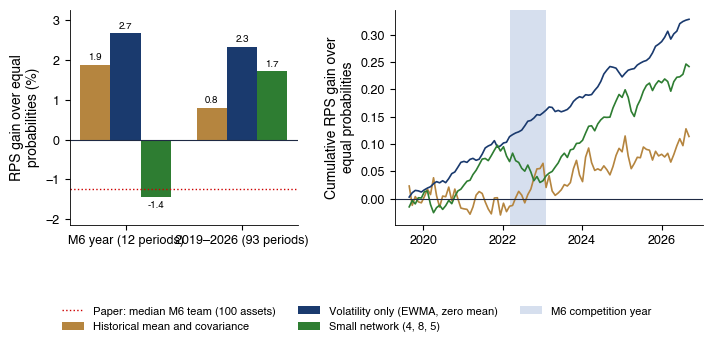

,sample,model,RPS,gain_pct,DM,p,better_periods_pct
0,M6 year (12 periods),Equal probabilities (benchmark),0.1516,0.0000,NaN,NaN,NaN
1,M6 year (12 periods),Historical mean and covariance,0.1487,1.8879,-0.5717,0.5675,75.0000
2,M6 year (12 periods),"Volatility only (EWMA, zero mean)",0.1475,2.6699,-6.9631,0.0000,91.6667
3,M6 year (12 periods),"Small network (4, 8, 5)",0.1538,-1.4379,1.0184,0.3085,41.6667
4,From July 2019 (93 periods),Equal probabilities (benchmark),0.1516,0.0000,NaN,NaN,NaN
5,From July 2019 (93 periods),Historical mean and covariance,0.1504,0.8066,-0.9190,0.3581,52.6882
6,From July 2019 (93 periods),"Volatility only (EWMA, zero mean)",0.1480,2.3316,-6.3461,0.0000,80.6452
7,From July 2019 (93 periods),"Small network (4, 8, 5)",0.1490,1.7169,-2.4142,0.0158,67.7419


In [18]:
idx, m6, ext, out = run()
res = summarise(m6, ext, out)
fig_rps(idx, m6, ext, out, res)
rows = []
for k, lab in (('m6', 'M6 year'), ('ext', 'From July 2019')):
    r = res[k]
    for m in ['U'] + MODELS:
        rows.append(dict(sample=f"{lab} ({r['n']} periods)", model=LBL[m], RPS=r[m] if m == 'U' else r[m]['rps'],
                         gain_pct=0.0 if m == 'U' else r[m]['gain'], DM=np.nan if m == 'U' else r[m]['dm'],
                         p=np.nan if m == 'U' else r[m]['p'],
                         better_periods_pct=np.nan if m == 'U' else r[m]['share_better']))
pd.DataFrame(rows).round(4)

![ch14_m6_rps](./ch14_m6_rps.png)

Output: `ch14_m6_rps.pdf`